# Fase 1 · Datos y preprocesamiento

**Detección de exoplanetas en Kepler con una red multirrama — iteración 2** (más datos, entrenamiento en GPU)

Curso de Deep Learning · Especialización en Inteligencia Artificial · Universidad Nacional de Colombia

**Autores:** Thomas Monnier Granda, Esteban Felipe Genes Noya, Juan Sebastian Higuita Riascos, Alexandra Arias Mazo y Eliel Segura Perez

> **Pregunta de este cuaderno:** ¿con qué datos se entrena, cómo se preparan y cómo se evita que la red haga trampa?

Este cuaderno no entrena nada: lee las evidencias que dejaron los pasos 1 a 5 (`iteracion_2/*.bat`) y las explica. Cada cifra sale de un archivo del repositorio.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import apoyo  # iteracion_2/notebooks/apoyo.py: rutas, lectura de evidencias y figuras

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
apoyo.estilo()
print("Raíz del repositorio:", apoyo.RAIZ.name, "| evidencias en", apoyo.EVIDENCIAS.relative_to(apoyo.RAIZ))

Raíz del repositorio: Proyecto_Final | evidencias en iteracion_2/evidencias


## 1. De 262 a 4.547 señales

La iteración 1 usó 262 señales. Con tan pocas, una red no puede ser grande ni mostrar que aprende de
las curvas. Aquí se toman **todas** las señales de Kepler (catálogo DR25) confirmadas como planeta o
descartadas como falso positivo, con periodo entre 1 y 30 días (así cada una tiene muchos tránsitos).

Cada señal produce **dos ejemplos**: la curva con su tránsito (planeta o falso positivo) y la misma
curva con el tránsito borrado, que es la clase *sin señal*. Por eso hay el doble de ejemplos que de señales.

In [2]:
base = apoyo.leer_json(apoyo.DATOS / "manifiesto_base.json")["resumen"]
ej = apoyo.ejemplos()
print(f"{base['n_kois']} señales de {base['n_estrellas']} estrellas → {base['n_ejemplos']} ejemplos")
por_clase = ej.groupby("clase").size().rename(index=dict(enumerate(apoyo.CLASES)))
display(por_clase.to_frame("ejemplos"))

4547 señales de 4007 estrellas → 9094 ejemplos


,ejemplos
clase,
planeta,2060
falso positivo,2487
sin señal,4547


## 2. Particiones por estrella: la primera defensa contra la fuga

Una estrella puede tener varias señales. Si una cae en entrenamiento y otra en prueba, la red podría
reconocer la estrella en lugar de la señal. Por eso las cinco particiones se reparten **por estrella**
(con un resumen criptográfico de su identificador, que no depende del azar). La celda lo comprueba.

Estrellas repartidas en más de una partición: 0 (debe ser 0)


,planeta,falso positivo,sin señal
particion,,,
0,420,496,916
1,409,495,904
2,428,502,930
3,404,496,900
4,399,498,897


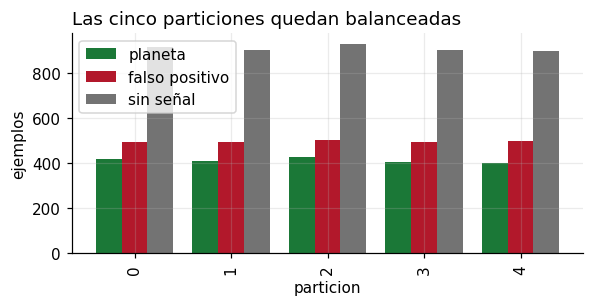

In [3]:
por_estrella = ej.groupby("kepid")["particion"].nunique()
print("Estrellas repartidas en más de una partición:", int((por_estrella > 1).sum()), "(debe ser 0)")
tabla = ej.pivot_table(index="particion", columns="clase", values="kepid", aggfunc="size")
tabla.columns = apoyo.CLASES
display(tabla)
fig, eje = plt.subplots(figsize=(6, 2.6))
tabla.plot.bar(ax=eje, color=apoyo.COLORES, width=0.8)
eje.set_ylabel("ejemplos"); eje.set_title("Las cinco particiones quedan balanceadas", loc="left")
apoyo.guardar(fig, "01_particiones")

## 3. Señales prerregistradas: lo que no se toca

Antes de entrenar se apartaron las señales cuya disposición difiere entre el catálogo DR25 y la tabla
acumulada del archivo de exoplanetas (su etiqueta cambió). No entran al
entrenamiento, ni a la búsqueda, ni a ninguna cifra de estos cuadernos: se evalúan **una sola vez**, al final.

In [4]:
print("Señales prerregistradas apartadas:", base["n_prerregistrados_kois"])
print("Ejemplos marcados como prerregistrados:", int(ej["prerregistrado"].sum()))

Señales prerregistradas apartadas: 76
Ejemplos marcados como prerregistrados: 152


## 4. Descarga y construcción de las entradas

Para cada estrella se descargaron sus curvas de luz (flujo PDCSAP, trimestres 1 a 17). El
preprocesamiento hace, en orden: quitar cadencias malas, quitar la tendencia lenta de la estrella
**sin** tocar los tránsitos, y plegar la curva con el periodo de la señal. De ahí salen tres entradas:

| Entrada | Forma | Rama que la usa |
|---|---|---|
| Vista global y vista local | 2001 y 201 puntos | Rama 1 (CNN 1D) |
| Tránsitos individuales | hasta 32 tránsitos de 61 puntos | Rama 2 (codificador por tránsito) |
| Escalares medidos en la curva | 7 números y 7 avisos de faltante | Rama 4 |

No todas las estrellas tienen datos suficientes; el registro lo deja contado.

Ejemplos construidos: 8942
  con vistas utilizables:    8649 (96.7%)
  con tránsitos utilizables: 8705 (97.3%)


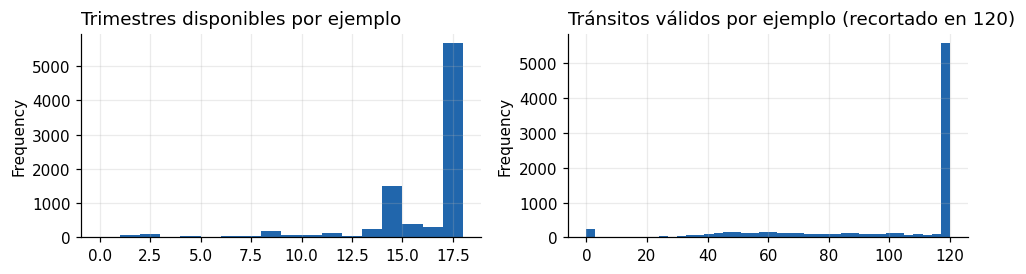

In [5]:
registro = pd.read_csv(apoyo.DATOS / "dataset_temporal_registro.csv")
resumen = apoyo.leer_json(apoyo.DATOS / "dataset_temporal.manifiesto.json")["resumen"]
n = resumen["n_ejemplos"]
print(f"Ejemplos construidos: {n}")
print(f"  con vistas utilizables:    {resumen['disponible_vistas']} ({resumen['disponible_vistas']/n:.1%})")
print(f"  con tránsitos utilizables: {resumen['disponible_transitos']} ({resumen['disponible_transitos']/n:.1%})")
fig, ejes = plt.subplots(1, 2, figsize=(9, 2.6))
registro["trimestres"].plot.hist(bins=range(0, 19), ax=ejes[0], color="#2166ac")
ejes[0].set_title("Trimestres disponibles por ejemplo", loc="left")
registro["transitos_validos"].clip(upper=120).plot.hist(bins=40, ax=ejes[1], color="#2166ac")
ejes[1].set_title("Tránsitos válidos por ejemplo (recortado en 120)", loc="left")
fig.tight_layout(); apoyo.guardar(fig, "01_cobertura")

## 5. Cómo ve la red cada clase

Tres ejemplos tomados **al azar con semilla fija** (no elegidos a mano), uno por clase. Si el dataset
completo no está en disco, se usa la muestra versionada de 60 ejemplos.

Usando: dataset completo · 8942 ejemplos


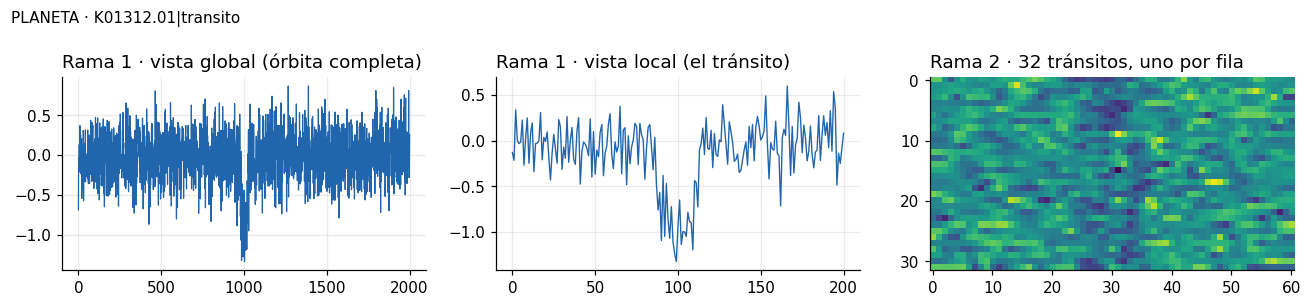

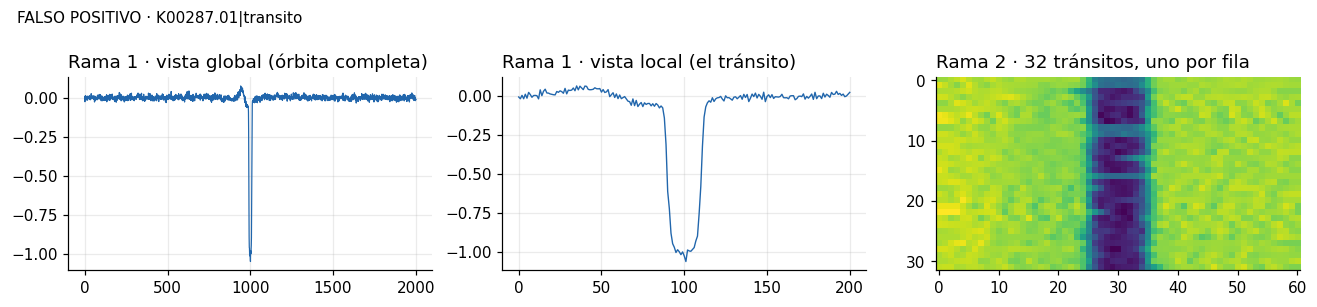

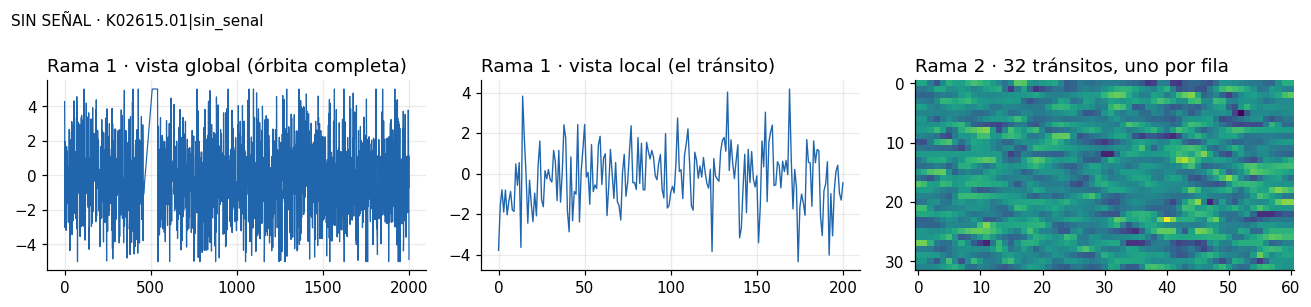

In [6]:
datos, origen = apoyo.dataset()
print("Usando:", origen, "·", len(datos["id_ejemplo"]), "ejemplos")
clase_de = ej.set_index("id_ejemplo")["clase"]
y = clase_de.loc[[str(i) for i in datos["id_ejemplo"]]].to_numpy()
rng = np.random.default_rng(protocolo_semilla := 0)
for c in range(3):
    i = int(rng.choice(np.flatnonzero((y == c) & (datos["disponible_vistas"] == 1) & (datos["disponible_transitos"] == 1))))
    fig = apoyo.ver_ejemplo(datos, i, f"{apoyo.CLASES[c].upper()} · {datos['id_ejemplo'][i]}")
    apoyo.guardar(fig, f"01_ejemplo_{c}")
    plt.show()

## 6. Escalares: qué entra y qué está prohibido

La rama 4 recibe siete números **medidos en la curva o propios de la geometría**, nunca la opinión
del catálogo. Las columnas que contienen la decisión de los revisores (`koi_score`, las banderas
`koi_fpflag_*`, `koi_pdisposition`) están prohibidas como entrada. La celda verifica que ninguna
se coló. Un dato que falta **no se rellena con cero a escondidas**: viaja con su aviso de faltante.
La segunda tabla muestra en qué clase falta el centroide.

In [7]:
p = apoyo.protocolo()
nombres = [str(n) for n in datos["nombres_escalares"]]
prohibidas = set(p["columnas_prohibidas_como_entrada"])
coladas = [n for n in nombres if n in prohibidas or n.startswith("koi_fpflag")]
print("Escalares de entrada:", nombres)
print("Columnas prohibidas :", sorted(prohibidas))
print("¿Alguna prohibida entre las entradas?:", coladas or "ninguna")
faltan = pd.Series(datos["faltantes"].mean(axis=0), index=nombres).rename("fracción faltante")
display(faltan.map("{:.1%}".format).to_frame())
centroide = pd.Series(datos["faltantes"][:, nombres.index("koi_dikco_msky")], name="centroide faltante")
display(centroide.groupby(pd.Series(y).map(dict(enumerate(apoyo.CLASES))).rename("clase")).mean().map("{:.1%}".format).to_frame())

Escalares de entrada: ['log10_periodo_d', 'log10_duracion_h', 'profundidad_medida_ppm', 'snr_medido', 'log10_n_transitos_validos', 'koi_dikco_msky', 'koi_dicco_msky']
Columnas prohibidas : ['koi_disposition', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_pdisposition', 'koi_score']
¿Alguna prohibida entre las entradas?: ninguna


,fracción faltante
log10_periodo_d,2.2%
log10_duracion_h,2.2%
profundidad_medida_ppm,2.2%
snr_medido,2.2%
log10_n_transitos_validos,2.2%
koi_dikco_msky,52.1%
koi_dicco_msky,52.3%


,centroide faltante
clase,
falso positivo,7.4%
planeta,0.5%
sin señal,100.0%


**Un atajo que hay que conocer.** Los ejemplos *sin señal* nunca tienen centroide (no hay tránsito del
cual medirlo), así que su aviso de faltante los delata. Por eso separar *sin señal* del resto es fácil
para la rama 4 y los aciertos de tres clases se leen con cautela. La métrica principal del proyecto,
el AUC de **planeta frente a falso positivo**, no usa los ejemplos *sin señal* y no se beneficia de ese
atajo. Entre planetas y falsos positivos el centroide también falta con distinta frecuencia: es una
señal leve que viene del catálogo y que el modelo tabular con centroide ve igualmente.

## Qué queda de esta fase

- 17 veces más señales que en la iteración 1, con las mismas reglas.
- Particiones por estrella verificadas, prerregistrados apartados, columnas con fuga fuera.
- Tres representaciones de la misma curva, una por rama. El siguiente cuaderno explica qué red lee cada una.